# 02 — Randomization Check (Step 3)

**Question:** Was the treatment/control assignment really random? If not, every later result (lift, uplift, ROI) could be wrong.

Checks:
1. **SRM (Sample Ratio Mismatch):** are the group sizes what the design intended? Design = **85:15**, not 50:50.
2. **Covariate balance:** do users in both groups look the same on the features? Measured with **SMD**, not p-values.
3. **Bonus:** classifier test. If no model can predict treatment from the features (AUC ≈ 0.5), the groups are balanced.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.data import load_criteo, FEATURES
from src.stats_tests import srm_test, balance_table

FIG = Path.cwd().parent / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")
df = load_criteo()
print(df.shape)

(1397959, 16)


## 3.1 SRM check

Chi-square goodness-of-fit: observed counts vs expected counts (85% / 15%).

For SRM we use a strict threshold of **p < 0.001** (industry convention). A p-value is the right tool here because the question is
binary ("is the assignment pipeline broken or not?"), and a large sample helps catch a real mismatch.

In [2]:
n_t = int((df.treatment == 1).sum())
n_c = int((df.treatment == 0).sum())

res = srm_test(n_t, n_c, expected_treatment_share=0.85)
pd.Series(res).to_frame("10% sample")

,10% sample
n,1397959
observed_treatment_share,0.85034
expected_treatment_share,0.85000
chi2,1.25973
p_value,0.26170
srm_detected,False


Check the full dataset (~14 million rows) too. Power is very high there, so even a small mismatch would be caught:

In [3]:
full = pd.read_parquet(Path.cwd().parent / "data" / "criteo_full.parquet", columns=["treatment"])
res_full = srm_test(int(full.treatment.sum()), int((full.treatment == 0).sum()), 0.85)
del full
pd.DataFrame({"10% sample": res, "full data": res_full})

,10% sample,full data
n,1397959,13979592
observed_treatment_share,0.85034,0.85000
expected_treatment_share,0.85000,0.85000
chi2,1.25973,0.00000
p_value,0.26170,0.99892
srm_detected,False,False


**What if we had wrongly assumed 50:50?** Using the wrong expected ratio raises a false SRM alarm:

In [4]:
wrong = srm_test(n_t, n_c, expected_treatment_share=0.50)
print(f"Expected 50:50 -> chi2={wrong['chi2']:,.0f}, p={wrong['p_value']:.2e}, SRM detected={wrong['srm_detected']}")
print(f"Expected 85:15 -> chi2={res['chi2']:,.2f}, p={res['p_value']:.3f}, SRM detected={res['srm_detected']}")

Expected 50:50 -> chi2=686,327, p=0.00e+00, SRM detected=True
Expected 85:15 -> chi2=1.26, p=0.262, SRM detected=False


## 3.2 Covariate balance: SMD

$$SMD = \frac{\bar{x}_T - \bar{x}_C}{\sqrt{(s_T^2 + s_C^2)/2}}$$

- SMD is an **effect size**: "how many standard deviations apart are the groups?". It does not grow with sample size.
- Rule of thumb: **|SMD| < 0.1** means balanced.
- The table also shows a t-test p-value, only for contrast.

In [5]:
bal = balance_table(df, FEATURES)
bal

,mean_treatment,mean_control,smd,abs_smd,t_test_p,balanced
feature,,,,,,
f3,4.17049,4.23419,-0.04914,0.04914,0.00000,True
f6,-4.18379,-3.99511,-0.04173,0.04173,0.00000,True
f5,4.02638,4.03877,-0.02973,0.02973,0.00000,True
f1,10.07036,10.06774,0.02635,0.02635,0.00000,True
f9,16.04486,15.89112,0.02217,0.02217,0.00000,True
f8,3.93341,3.93457,-0.02054,0.02054,0.00000,True
f7,5.10554,5.08309,0.01885,0.01885,0.00000,True
f2,8.44610,8.44927,-0.01057,0.01057,0.00001,True
f4,10.33952,10.33643,0.00914,0.00914,0.00010,True


In [6]:
print(f"Max |SMD| = {bal.abs_smd.max():.4f}  (threshold 0.1)")
print(f"All features balanced: {bal.balanced.all()}")
print(f"Features with t-test p < 0.05: {(bal.t_test_p < 0.05).sum()} / {len(bal)}")

Max |SMD| = 0.0491  (threshold 0.1)
All features balanced: True
Features with t-test p < 0.05: 11 / 12


### Love plot (SMD per feature)

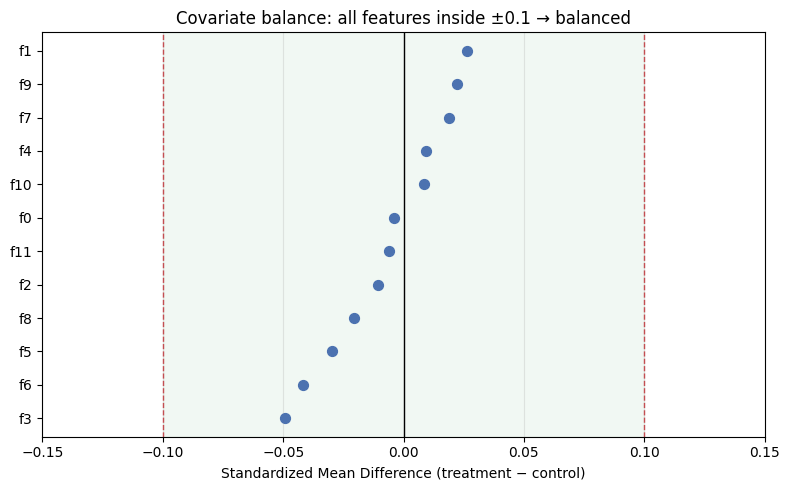

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
order = bal.sort_values("smd")
ax.scatter(order.smd, order.index, color="#4C72B0", s=50, zorder=3)
ax.axvline(0, color="black", lw=1)
for x in (-0.1, 0.1):
    ax.axvline(x, color="#C44E52", ls="--", lw=1)
ax.axvspan(-0.1, 0.1, color="#55A868", alpha=0.08)
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("Standardized Mean Difference (treatment − control)")
ax.set_title("Covariate balance: all features inside ±0.1 → balanced")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "02_love_plot.png", dpi=110)
plt.show()

## 3.3 Why not p-values? (interview point)

P-values shrink as the sample grows. Take a **fixed, tiny** difference (SMD = 0.01, practically zero) and increase only n:

In [8]:
rng = np.random.default_rng(42)
true_smd = 0.01
rows = []
for n in [1_000, 10_000, 100_000, 1_000_000, 10_000_000]:
    n_t_, n_c_ = int(n * 0.85), int(n * 0.15)
    # expected t-stat for a fixed SMD with an 85:15 split
    se = np.sqrt(1 / n_t_ + 1 / n_c_)
    z = true_smd / se
    rows.append({"n_users": n, "true_SMD": true_smd, "z": z, "p_value": 2 * stats.norm.sf(z)})
pd.DataFrame(rows)

,n_users,true_SMD,z,p_value
0,1000,0.01000,0.11292,0.91010
1,10000,0.01000,0.35707,0.72104
2,100000,0.01000,1.12916,0.25883
3,1000000,0.01000,3.57071,0.00036
4,10000000,0.01000,11.29159,0.00000


The SMD stays at 0.01, yet with 10 million users the p-value is almost 0. **On large data a p-value tells you whether a difference
exists, not how big it is.** A balance check asks "how big?", so we use SMD.

## 3.4 Bonus: classifier balance test

If randomization worked, no model should be able to tell from the features whether a user is in treatment or control.
Test AUC should be ≈ 0.5. This test also catches imbalance in feature *interactions*, which per-feature SMD can miss.

In [9]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

X_tr, X_te, y_tr, y_te = train_test_split(df[FEATURES], df.treatment, test_size=0.3,
                                          stratify=df.treatment, random_state=42)
clf = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, verbose=-1)
clf.fit(X_tr, y_tr)
auc = roc_auc_score(y_te, clf.predict_proba(X_te)[:, 1])

# Null distribution: same model on shuffled labels -> what AUC looks like with zero signal
null_aucs = []
for s in range(5):
    y_perm = y_tr.sample(frac=1, random_state=s).values
    m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, verbose=-1).fit(X_tr, y_perm)
    null_aucs.append(roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]))
print(f"Treatment-prediction AUC: {auc:.4f}")
print(f"Shuffled-label AUCs:      {np.round(null_aucs, 4)} (mean {np.mean(null_aucs):.4f})")

Treatment-prediction AUC: 0.5111
Shuffled-label AUCs:      [0.5006 0.502  0.496  0.4981 0.4998] (mean 0.4993)


## Summary

In [10]:
print(f"SRM (10%):  observed {res['observed_treatment_share']:.4%} vs 85%  p={res['p_value']:.3f}  -> SRM: {res['srm_detected']}")
print(f"SRM (full): observed {res_full['observed_treatment_share']:.4%} vs 85%  p={res_full['p_value']:.2e}  -> SRM: {res_full['srm_detected']}")
print(f"Balance:    max |SMD| = {bal.abs_smd.max():.4f} -> all < 0.1: {bal.balanced.all()}")
print(f"Classifier: AUC = {auc:.4f} (null ~ {np.mean(null_aucs):.4f})")

SRM (10%):  observed 85.0339% vs 85%  p=0.262  -> SRM: False
SRM (full): observed 85.0000% vs 85%  p=9.99e-01  -> SRM: False
Balance:    max |SMD| = 0.0491 -> all < 0.1: True
Classifier: AUC = 0.5111 (null ~ 0.4993)


## Key takeaways (Step 3)

1. **SRM: pass.** Treatment share in the 10% sample is 85.03% vs 85% expected (χ² = 1.26, p = 0.26). No mismatch.
   Had we wrongly expected 50:50, χ² would be ≈ 686,000 and we would raise a false SRM alarm.
2. **The full data has *exactly* 85.000% treatment** (p ≈ 1.0). Real random assignment does not land this exactly,
   so Criteo most likely curated/subsampled the dataset to this ratio. The SRM test on the full data therefore says little;
   our 10% random sample is the meaningful check. (Goes into the limitations section.)
3. **Covariate balance: pass.** All 12 features have |SMD| < 0.05 (max f3 = 0.049), well below the 0.1 threshold.
4. **Live example of the p-value trap:** 11 of 12 features have t-test p < 0.05 *even though* SMD is practically zero.
   Reading p-values would wrongly conclude "randomization failed". The simulation shows the same: at SMD = 0.01,
   n = 1,000 gives p = 0.91 while n = 10 million gives p ≈ 0.
5. **Classifier test:** AUC 0.511 vs 0.496–0.502 for shuffled labels. There is a *very weak* signal above random noise,
   practically negligible (0.5 = coin flip), but it hints at a small imbalance in some feature combination.
   **Action:** Step 6 also reports a regression-adjusted lift using the features as covariates, so this imbalance does not bias the
   estimate (and variance drops).

**Verdict:** Randomization looks trustworthy. A direct treatment vs control comparison (ITT) is valid.

## ⚠️ Update after Step 6

The Step 3 verdict ("randomization trustworthy") was **incomplete**. Step 6 adds a *prognostic score* check: a model trained only on
control users that predicts visit from the features. By that score, the treatment group's expected visit rate is 0.27 pp higher (z ≈ 10.5).
The per-feature SMDs were small (< 0.05), but the features predict visit strongly, so many small imbalances add up to a meaningful bias.
The classifier AUC above (0.511 vs a null of 0.499) was the hint.

**Revised verdict:** the assignment ratio (SRM) is fine, but the features show a systematic imbalance, probably because the dataset
pools several separate tests. The lift is therefore also reported covariate-adjusted (see `05_ab_test.ipynb`).